<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 5.5 - Time Series Data (Bonus)</h2>
<p>Time order changes the meaning of an observation. The slide examples compare several recorded series, followed by optional demonstrations using bicycle counts, temperature and a constructed infrastructure sensor record.</p>
<p>Central question: which patterns reflect time order, and which operations help describe those patterns?</p>
<p>After this notebook, you should distinguish trend, seasonality and cycles, read lagged comparisons, choose an aggregation with suitable units, and distinguish a missing reading from zero.</p>
<a id="lecture-structure"></a>
<h3>Lecture Structure</h3>
<ol><li><a href="#section1">Stacked Overflow Questions</a></li>
<li><a href="#section2">S&amp;P500</a></li>
<li><a href="#section3">Bike Traffic Data</a></li>
<li><a href="#section4">Canada COVID Cases</a></li>
<li><a href="#section5">Earthquakes</a></li>
<li><a href="#section6">Land Temperature</a></li>
<li><a href="#section7">Lynx Trappings</a></li>
<li><a href="#section8">Brick Production</a></li>
<li><a href="#section9">White Noise</a></li>
<li><a href="#section10">Red Meat Slaughter</a></li>
<li><a href="#section11">Stationarity</a></li></ol>
<p><a href="#lecture-summary">Lecture summary</a></p>
<h3>Optional extensions</h3>
<ol start="12"><li><a href="#section12">Ordering and aggregation</a></li>
<li><a href="#section13">Seasonal profiles and decomposition</a></li>
<li><a href="#section14">An infrastructure sensor record</a></li></ol>
<p>Run Setup Notebook first. Follow the numbered section links from the slides. Run each section in order. The optional extensions follow the lecture summary.</p>
<h3>Sources and documentation</h3>
<p><a href="../slides/week5_lecture5.pptx">Lecture slides</a> | <a href="DATA_SOURCES.html">Dataset sources, fields and limitations</a> | <a href="https://pandas.pydata.org/docs/user_guide/timeseries.html">pandas time-series guide</a></p>

<h2>Setup Notebook</h2>
<p>The course environment supplies NumPy, pandas, Seaborn and Matplotlib. All data files are local. The random examples use seed 538.</p>
<p>Data operations stay visible below. Repeated figure layouts live in <a href="utils.py">utils.py</a>.</p>

In [1]:
# Third-party libraries
import numpy as np
import pandas as pd

# Local plotting defaults
import utils
from utils import configure_plots

%matplotlib inline
RANDOM_STATE = 538
rng = np.random.default_rng(RANDOM_STATE)
configure_plots()
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_rows', 8)

<a id='section1'></a>
<h2>1. Stacked Overflow Questions</h2>
<p>Question: What changes when several measurements share the same time axis? Compare the existing plots while keeping the monthly observation interval in mind.</p>

In [2]:
stacked_overflow = pd.read_csv('stacked_overflow.csv')
stacked_overflow['month'] = pd.to_datetime(stacked_overflow['month'], format='%y-%b')
stacked_overflow.head()

,month,nltk,spacy,stanford-nlp,...,Lasagne,OCR,Apache-spark-mlib,azure-virtual-machine
0,2009-01-01,0,0,0,...,0,5,0,0
1,2009-02-01,1,0,0,...,0,11,0,0
2,2009-03-01,0,0,0,...,0,2,0,0
3,2009-04-01,0,0,0,...,0,5,0,0
4,2009-05-01,1,0,0,...,0,3,0,0


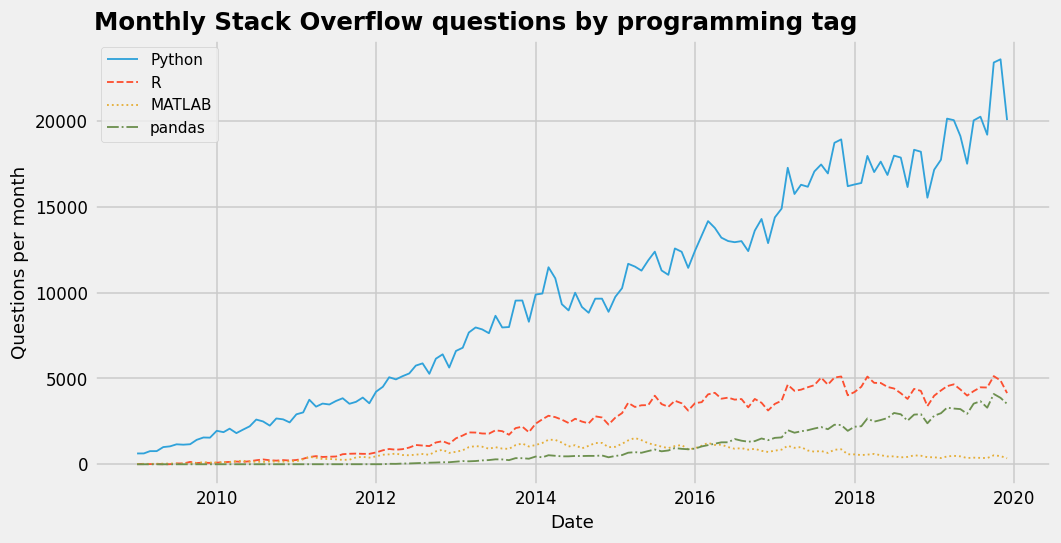

In [3]:
utils.plot_programming_questions(stacked_overflow)

<p>Each curve counts monthly questions for one programming tag. A larger count describes more tagged questions, rather than the number of users.</p>

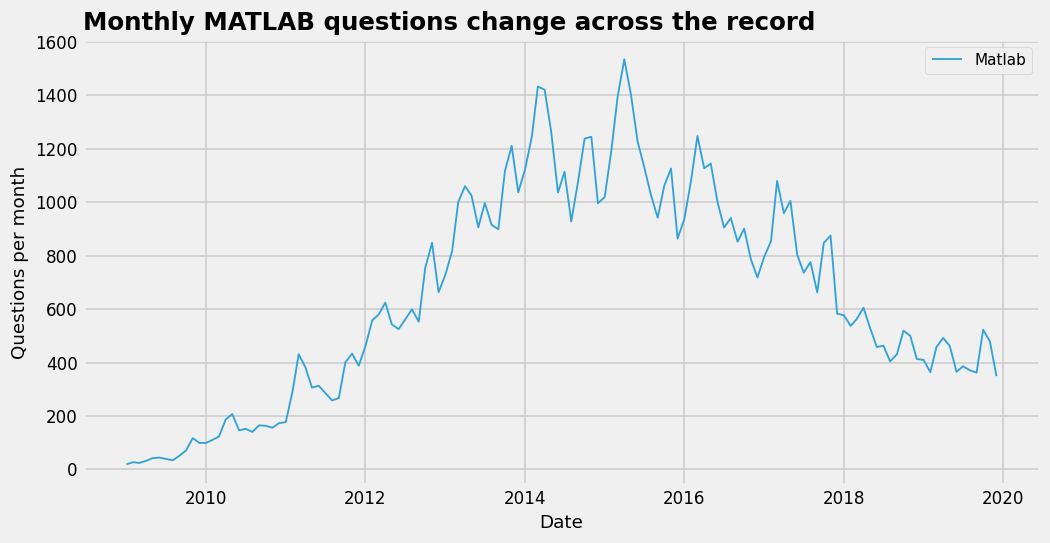

In [4]:
utils.plot_matlab_questions(stacked_overflow)

<p>The separate MATLAB view makes changes within one series easier to read. The dates and observations match the preceding chart.</p>

<p>Takeaway: Shared dates support comparisons across series. Separate views reveal changes hidden by a larger series.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section2'></a><h2>2. S&amp;P500</h2>
<p>Question: how do a price level and its day-to-day change differ?</p>
<p>The local extract records SPY closing prices from 2010–2020. SPY is an exchange-traded fund tracking the S&amp;P 500. These prices use dollars per share rather than index points.</p>

<h3>Load the fixed price record</h3>
<p>The supplied CSV replaces the live download for classroom use. No package installation or network request is needed during the demonstration.</p>

<p>The <a href="DATA_SOURCES.html">source record</a> documents the fixed date range, price field and data retrieval. A first difference subtracts the previous trading-day close.</p>

In [5]:
sp500 = pd.read_csv('spy_daily_close_2010_2020.csv', parse_dates=['Date'], index_col='Date')
sp500['change'] = sp500['Close'].diff()
sp500.head()

,Close,change
Date,,
2010-01-04,113.330002,NaN
2010-01-05,113.629997,0.299995
2010-01-06,113.709999,0.080002
2010-01-07,114.190002,0.480003
2010-01-08,114.570000,0.379998


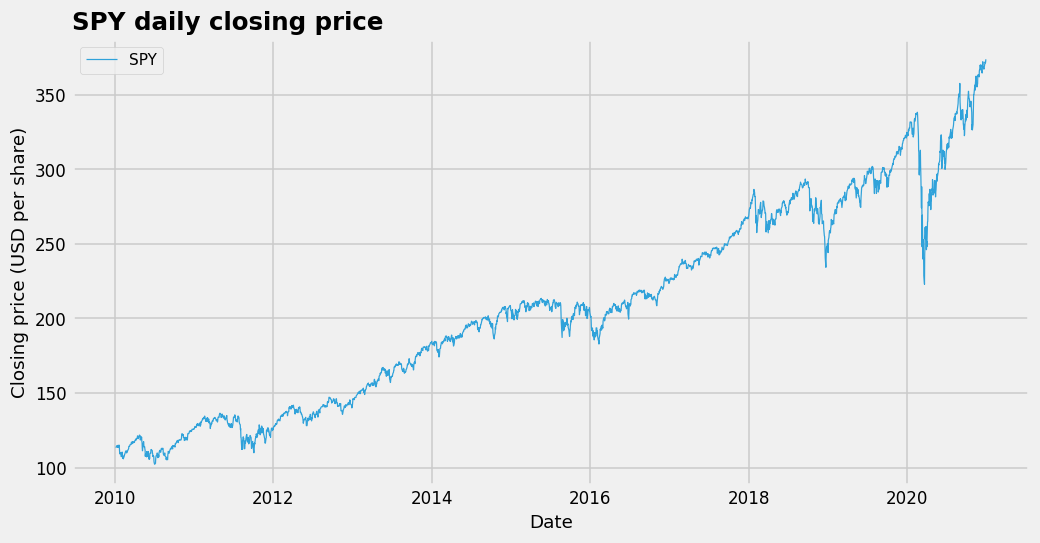

In [6]:
utils.plot_price_history(sp500)

<h3>Compare changes between trading days</h3>
<p>The price level compares trading days across the recorded decade. The next chart measures the change between adjacent trading days.</p>

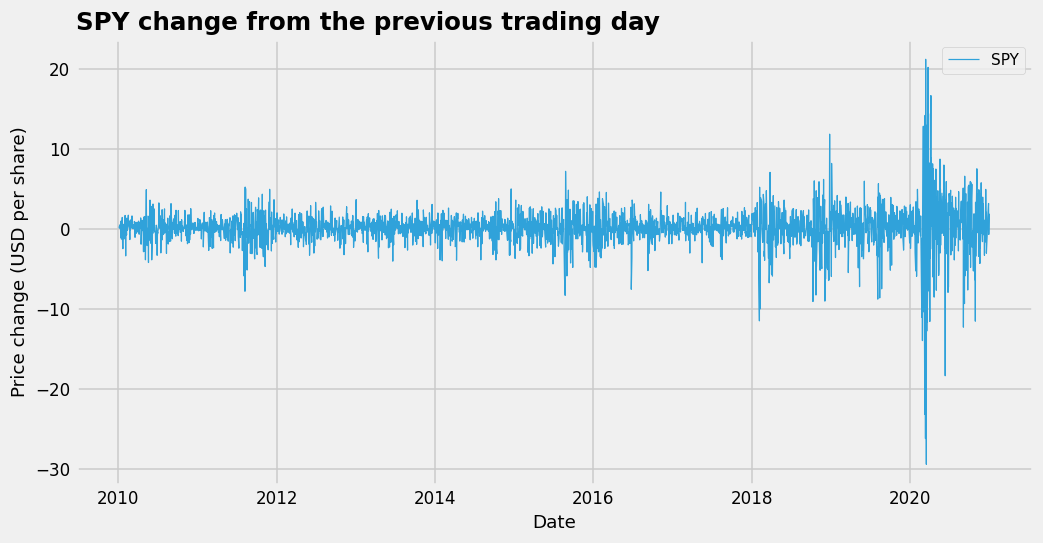

In [7]:
utils.plot_price_changes(sp500)

<p>Positive differences indicate a higher close than the preceding trading day. The first row has no preceding observation, so its difference is missing.</p>

<h3>Inspect a shorter time window</h3>

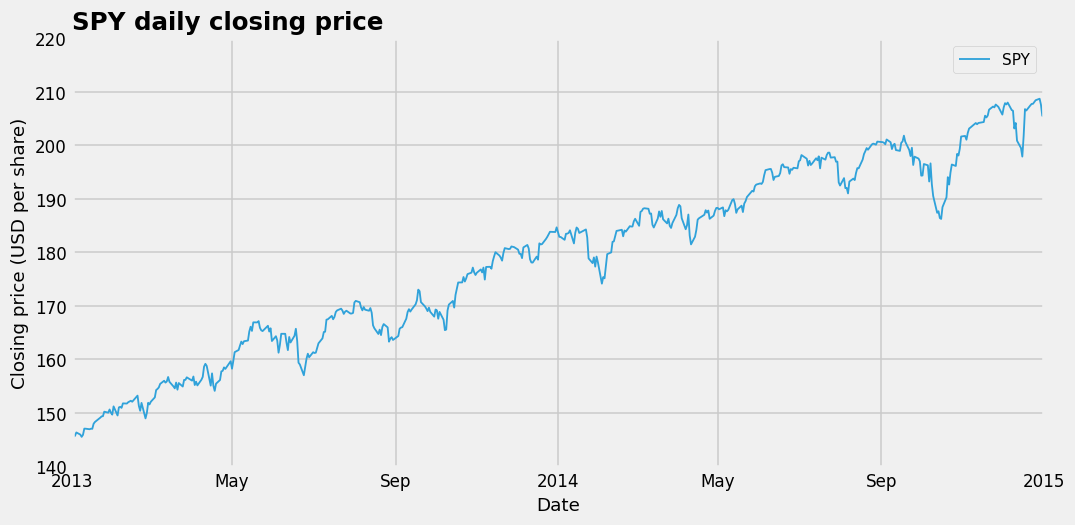

In [8]:
utils.plot_price_window(sp500)

<p>The fixed 2013–2014 window isolates a shorter interval without changing the underlying prices.</p>

<p>Takeaway: A price level and its first difference answer different questions. Trading-day gaps also differ from calendar-day gaps.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section3'></a>
<h2>3. Bike Traffic Data</h2>
<p>Question: What temporal patterns are visible in the bridge counts? Read the observation interval and axis labels before interpreting the peaks.</p>

In [9]:
bike_data = pd.read_csv('bike_traffic_data.csv')
bike_data['Date'] = pd.to_datetime(bike_data['Date'], format='%m/%d/%Y %I:%M:%S %p')
bike_data.head()

,Date,Fremont Bridge West Sidewalk,Fremont Bridge East Sidewalk
0,2012-10-03 00:00:00,9.0,4.0
1,2012-10-03 01:00:00,6.0,4.0
2,2012-10-03 02:00:00,1.0,1.0
3,2012-10-03 03:00:00,3.0,2.0
4,2012-10-03 04:00:00,1.0,6.0


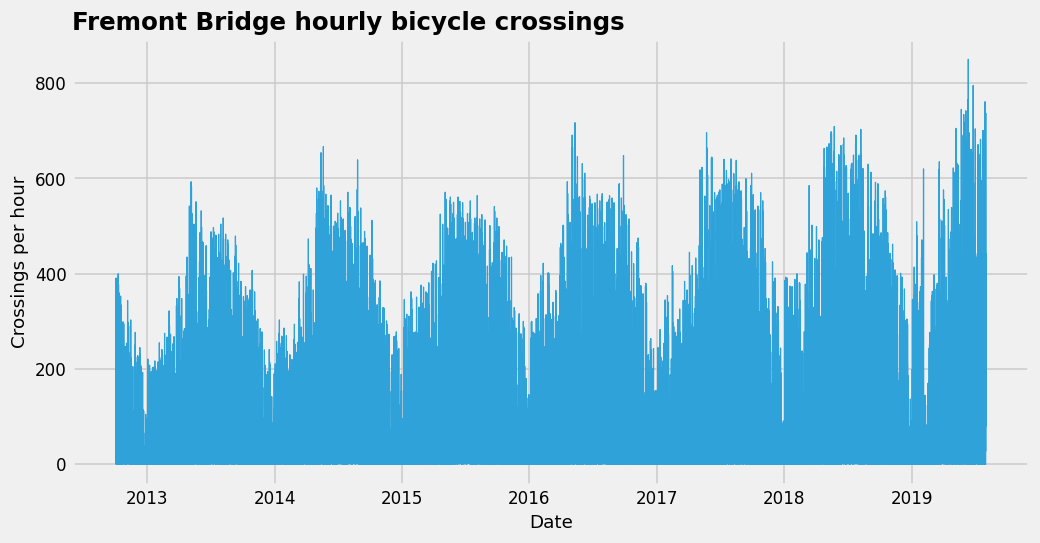

In [10]:
utils.plot_bridge_history(bike_data)

<p>The full record hides much of the hourly pattern. Optional section 12 compares one week and aggregates complete days.</p>

<p>Takeaway: Time resolution determines which traffic patterns are visible.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section4'></a>
<h2>4. Canada COVID Cases</h2>
<p>Question: How does the plotted COVID series change over time? The existing plot uses the seven-day-average column from the supplied data.</p>

In [11]:
canada_covid = pd.read_csv('covid19_canada.csv')
canada_covid = canada_covid[canada_covid['prname'] == 'Canada']
canada_covid['date'] = pd.to_datetime(canada_covid['date'])
canada_covid.head()

,pruid,prname,prnameFR,date,...,avgtotal_last7,avgincidence_last7,avgdeaths_last7,avgratedeaths_last7
2,1,Canada,Canada,2020-01-31,...,NaN,NaN,NaN,NaN
5,1,Canada,Canada,2020-02-08,...,NaN,NaN,NaN,NaN
8,1,Canada,Canada,2020-02-16,...,NaN,NaN,NaN,NaN
11,1,Canada,Canada,2020-02-21,...,NaN,NaN,NaN,NaN
14,1,Canada,Canada,2020-02-24,...,NaN,NaN,NaN,NaN


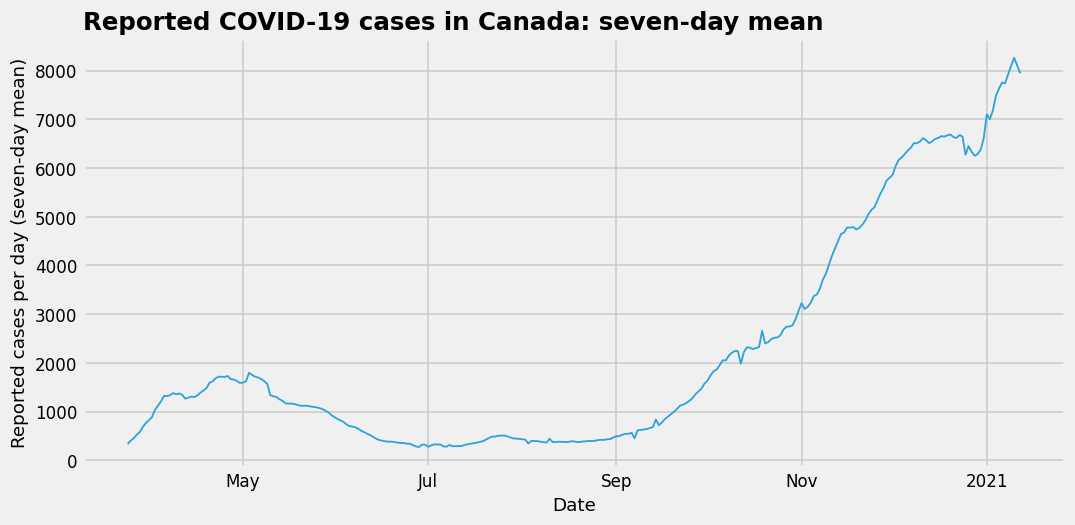

In [12]:
utils.plot_reported_cases(canada_covid)

<p>The supplied seven-day average smooths daily reporting fluctuations. The curve describes reported cases, rather than every infection.</p>

<p>Takeaway: A rolling average smooths a reported count series and changes the meaning of each plotted value.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section5'></a>
<h2>5. Earthquakes</h2>
<p>Question: how does monthly aggregation change the event record? Each plotted count combines the events recorded in one calendar month.</p>

In [13]:
earthquakes = pd.read_csv('earthquakes.csv')
earthquakes = earthquakes.set_index(pd.to_datetime(earthquakes['time']))
earthquakes = earthquakes.resample('ME').count()
earthquakes.head()

,time,latitude,longitude,depth,...,magNst,status,locationSource,magSource
time,,,,,,,,,
1973-03-31 00:00:00+00:00,1,1,1,1,...,0,1,1,1
1973-04-30 00:00:00+00:00,0,0,0,0,...,0,0,0,0
1973-05-31 00:00:00+00:00,1,1,1,1,...,0,1,1,1
1973-06-30 00:00:00+00:00,0,0,0,0,...,0,0,0,0
1973-07-31 00:00:00+00:00,0,0,0,0,...,0,0,0,0


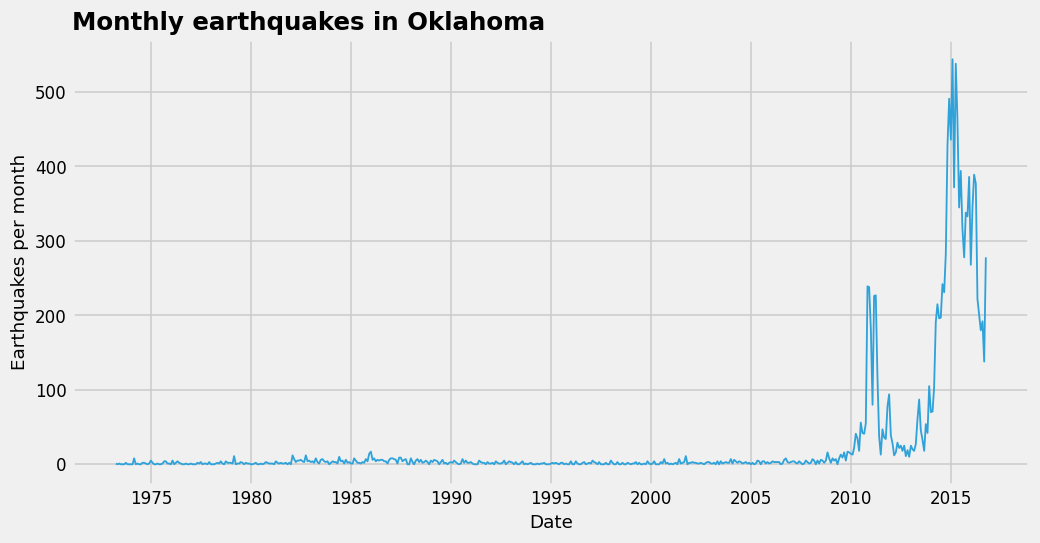

In [14]:
utils.plot_earthquake_counts(earthquakes)

<p>Monthly counts combine individual event times. The apparent changes depend on the catalogue coverage and detection process as well as earthquake activity.</p>

<p>Takeaway: Aggregation replaces event times with counts per interval.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section6'></a>
<h2>6. Land Temperature</h2>
<p>Question: how does a rolling mean reveal slower variation? Compare monthly measurements with a trailing twelve-month average.</p>

<h3>Calculate a trailing temperature average</h3>

In [15]:
city_temperatures = pd.read_csv('city_temperatures.csv')
city_temperatures['dt'] = pd.to_datetime(city_temperatures['dt'])
city_temperatures = city_temperatures.set_index(city_temperatures['dt'])
city_temperatures.head()

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
dt,,,,,,,
1841-01-01,1841-01-01,19.101,4.244,Melbourne,Australia,37.78S,144.41E
1841-02-01,1841-02-01,19.744,2.995,Melbourne,Australia,37.78S,144.41E
1841-03-01,1841-03-01,16.611,4.420,Melbourne,Australia,37.78S,144.41E
1841-04-01,1841-04-01,12.269,1.766,Melbourne,Australia,37.78S,144.41E
1841-05-01,1841-05-01,10.275,1.188,Melbourne,Australia,37.78S,144.41E


In [16]:
city_temperatures_yearly = city_temperatures['AverageTemperature'].rolling(window=12).mean().to_frame()

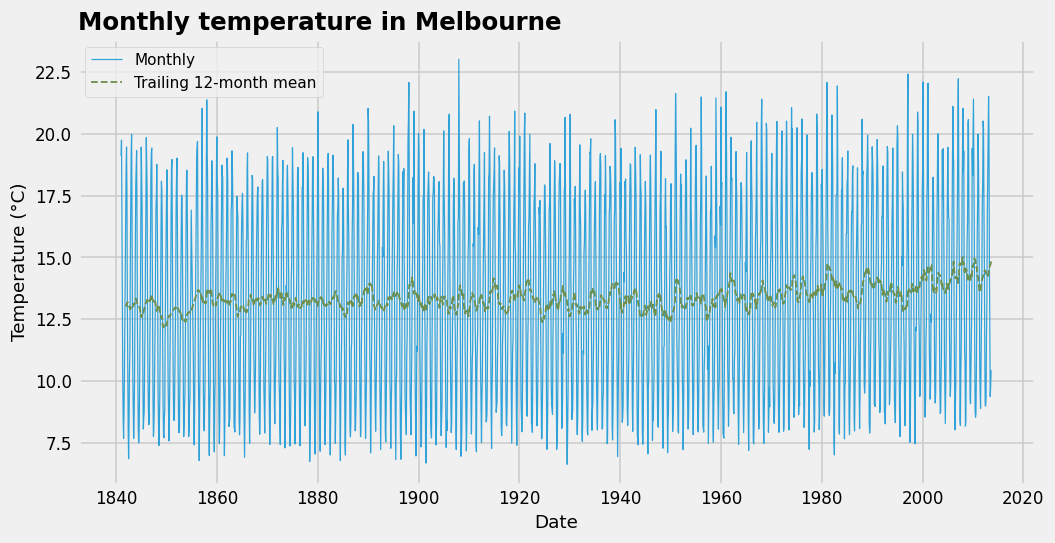

In [17]:
utils.plot_temperature_and_rolling_mean(city_temperatures, city_temperatures_yearly)

<p>The trailing mean reduces the annual temperature swing. Twelve complete monthly values are needed for each rolling average.</p>

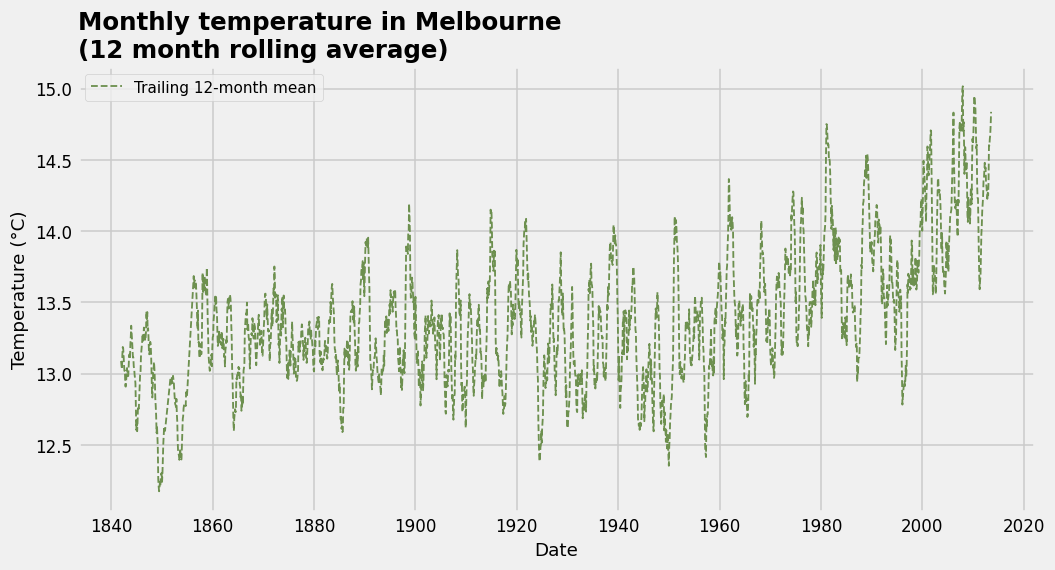

In [18]:
utils.plot_temperature_rolling_mean(city_temperatures_yearly)

<p>The narrower vertical range exposes slower variation. A rolling mean summarizes the series without establishing a cause.</p>

<p>Takeaway: Seasonal variation and slower changes coexist in the same temperature record.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section7'></a>
<h2>7. Lynx Trappings</h2>
<p>Question: What does a lagged comparison reveal about the trapping cycles? Run the annual-series plot before comparing the shifted values and autocorrelations.</p>

In [19]:
lynx = pd.read_csv('Annual_Canadian_Lynx_trappings.csv', index_col=0)
lynx.head()

,X,time,value
1,1,1821,269
2,2,1822,321
3,3,1823,585
4,4,1824,871
5,5,1825,1475


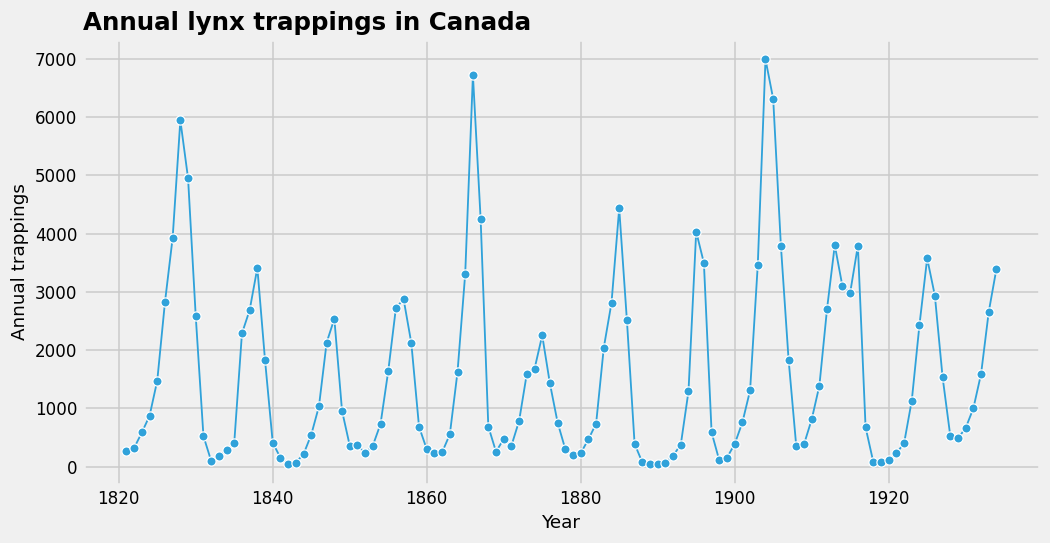

In [20]:
utils.plot_lynx_counts(lynx)

<h3>Compare observations at different lags</h3>
<p>The annual counts rise and fall over several years. These are trapping records rather than a direct population census.</p>

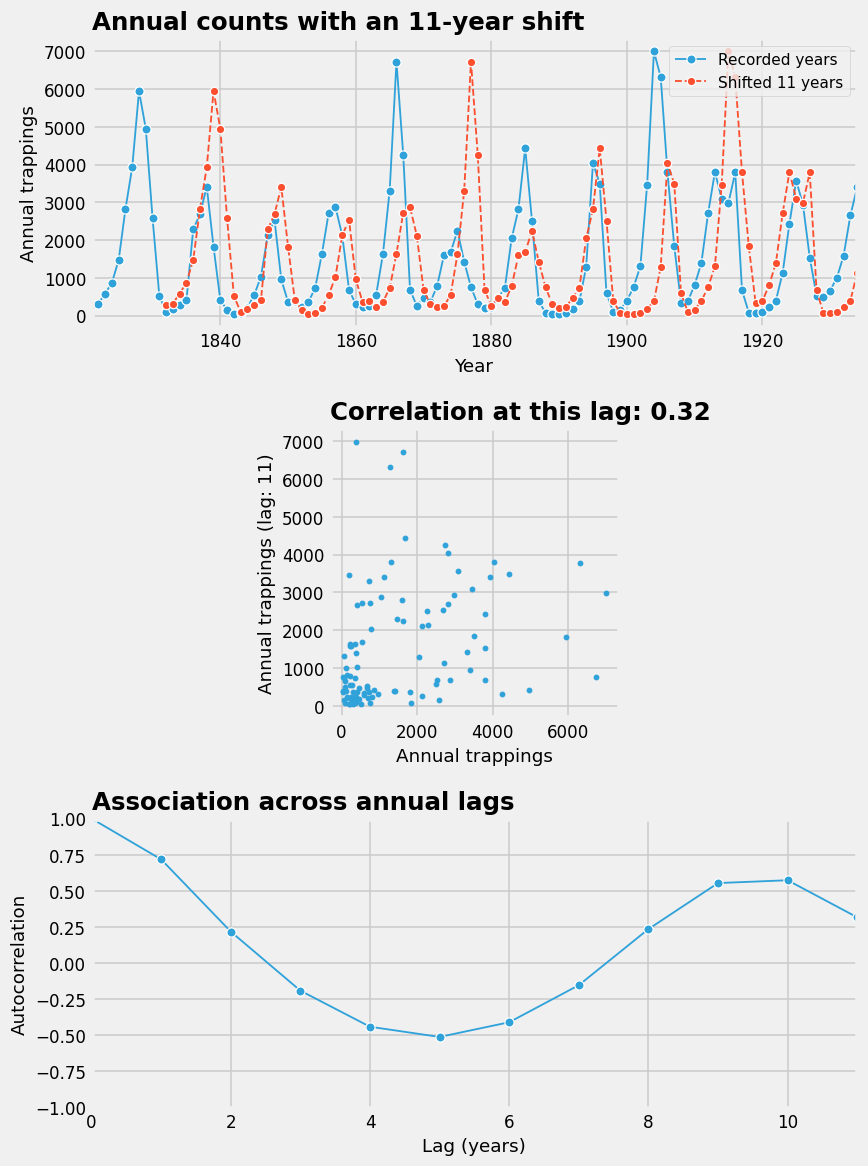

In [21]:
lag = 11
corr = np.corrcoef(lynx['value'].iloc[0:-lag], lynx['value'].iloc[lag:])[0, 1]
lags = np.arange(0, lag+1)
corrs = [lynx['value'].autocorr(lag=k) if k else 1 for k in lags]
utils.plot_lynx_lag_comparison(lynx, lag, corr, lags, corrs)

<p>The first panel overlays an eleven-year shift. The second pairs observations eleven years apart. The third repeats the calculation across several lags.</p>

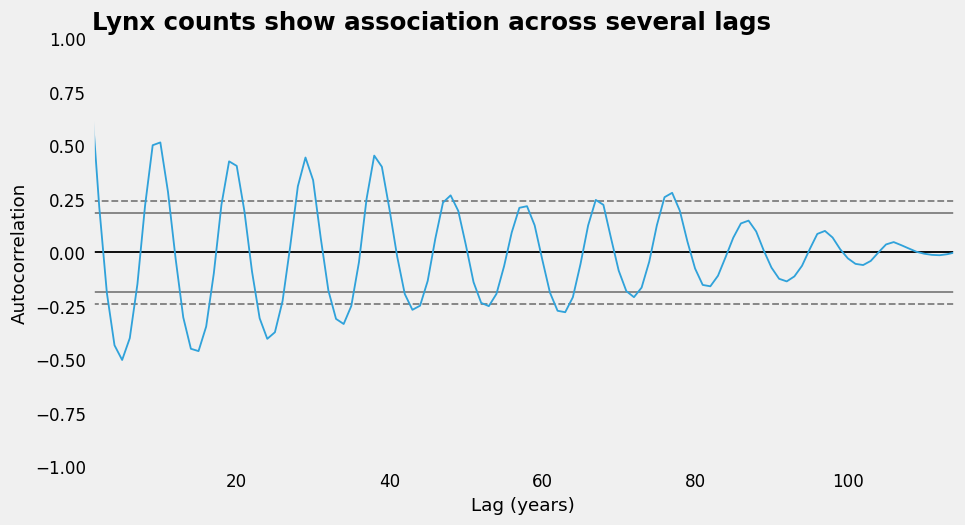

In [22]:
utils.plot_lynx_autocorrelation(lynx)

<p>Positive peaks indicate similar values at separated years. Trend, repeating variation and sampling noise all influence autocorrelation.</p>

<p>Takeaway: Lagged correlation measures association between a series and a shifted copy.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section8'></a>
<h2>8. Brick Production</h2>
<p>Question: which patterns coexist in quarterly production data? Compare changes across years with the shorter repeating variation.</p>

In [23]:
bricks = pd.read_csv('brick_production.csv', names=['val'])
bricks['date'] = pd.date_range('8/1/1955', '6/1/1994', freq='QE')
bricks.head()

,val,date
0,189,1955-09-30
1,204,1955-12-31
2,208,1956-03-31
3,197,1956-06-30
4,187,1956-09-30


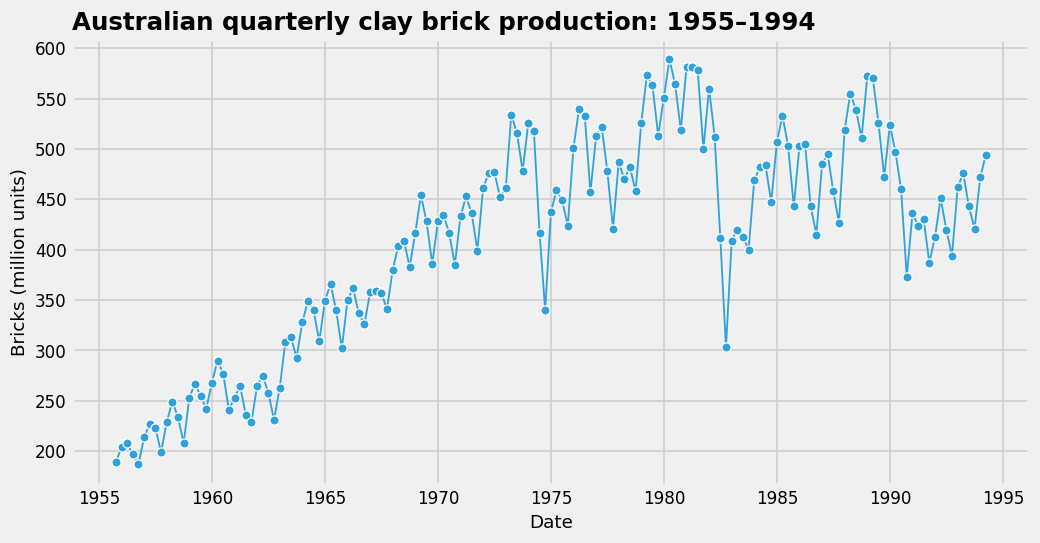

In [24]:
utils.plot_brick_production(bricks)

<p>The quarterly series contains both longer changes and shorter repeating variation. One observation represents a quarter.</p>

<p>Takeaway: Quarterly data describe variation at a different resolution from daily or annual data.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section9'></a>
<h2>9. White Noise</h2>
<p>Question: what does the autocorrelation of independent random values look like? The fixed seed reproduces this realization. A different seed produces different small sample correlations.</p>

In [25]:
white_noise = pd.DataFrame({'values': rng.random(100)})

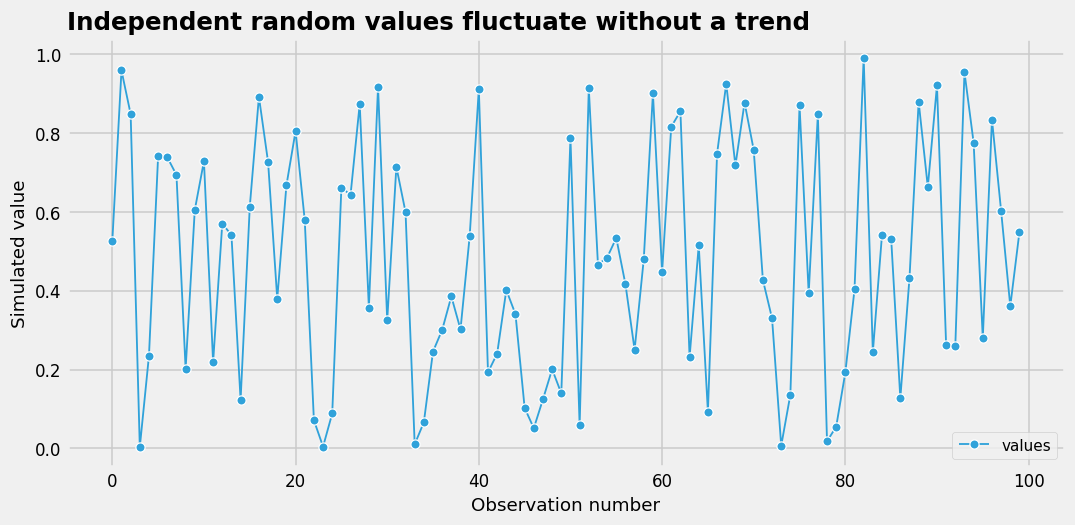

In [26]:
utils.plot_white_noise(white_noise)

<p>These independent uniform draws use a fixed seed. The sequence has no imposed trend or seasonal cycle.</p>

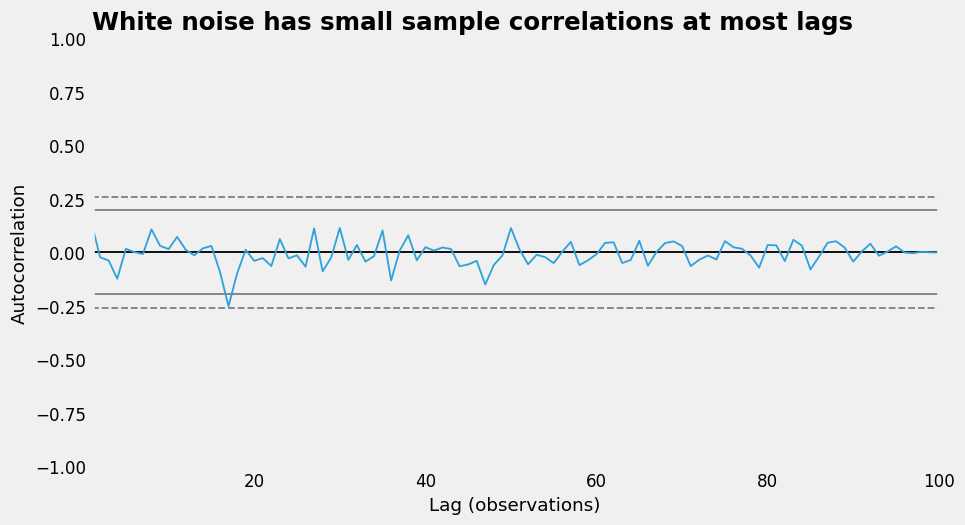

In [27]:
utils.plot_white_noise_autocorrelation(white_noise)

<p>Small nonzero correlations occur in a finite random sample. The plotted bands use approximate assumptions and are not proof of independence.</p>

<p>Takeaway: Independent random observations still produce nonzero sample correlations.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section10'></a>
<h2>10. Red Meat Slaughter</h2>
<p>Question: does the time plot reveal the full pattern? Follow the cattle counts from dated monthly reporting periods to lagged association.</p>

In [28]:
red_meat = pd.read_csv('monthly_red_meat_slaughter.csv')
red_meat['EndDt_DtFin'] = pd.to_datetime(red_meat['EndDt_DtFin'])
red_meat.head()

,EndDt_DtFin,MjrCmdtyEn_PrdtPrncplAn,MjCmdtyFr_PrdtPrncplFr,CtgryEn_CtgrieAn,CtgryFr_CtgrieFr,NumHd_NmbTetes
0,1998-01-24,Calves,Veaux,Female,Femelle,4834
1,1998-01-24,Calves,Veaux,Male,Male,18627
2,1998-01-24,Cattle,Bovins,Bulls,Taureaux,1618
3,1998-01-24,Cattle,Bovins,Cows,Vaches,49722
4,1998-01-24,Cattle,Bovins,Heifers,Genisses,73843


In [29]:
cattle = red_meat[red_meat['MjrCmdtyEn_PrdtPrncplAn'] == 'Cattle']
cattle = cattle.set_index('EndDt_DtFin')
cattle = cattle.groupby(cattle.index).sum(numeric_only=True)
cattle.head()

,NumHd_NmbTetes
EndDt_DtFin,
1998-01-24,243028
1998-02-21,248279
1998-03-28,296578
1998-04-25,245290
1998-05-23,263970


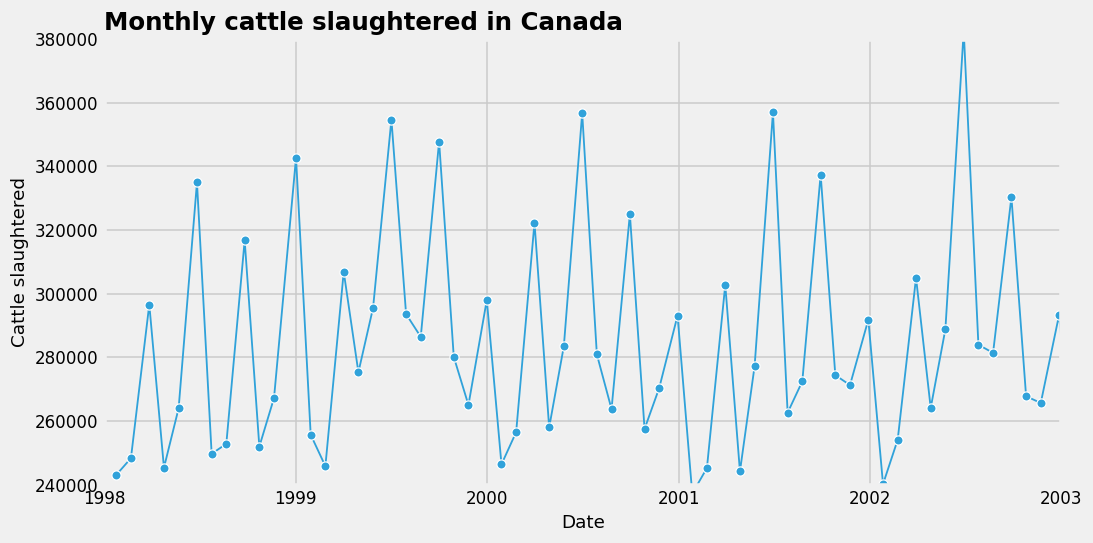

In [30]:
utils.plot_cattle_counts(cattle)

<p>This window shows counts from the supplied reporting periods. The repeated rises and falls motivate the lagged comparison.</p>

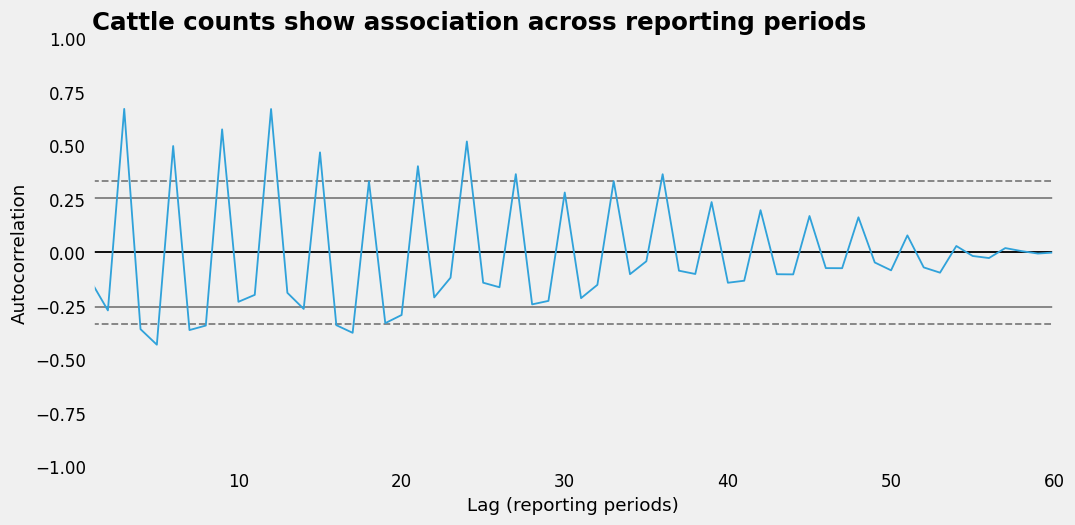

In [31]:
utils.plot_cattle_autocorrelation(cattle)

<p>The calculation uses the numerical cattle-count column alone. Lag 1 compares consecutive reporting periods.</p>

<p>Takeaway: A correlogram supplements the time plot when examining repeated variation.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section11'></a>
<h2>11. Stationarity</h2>
<p>Question: Which changes make a time series non-stationary? Compare the prepared random examples, then inspect the difference of the cumulative random walk.</p>

<h3>Start with stable random variation</h3>

In [32]:
time_series = pd.DataFrame({'values': rng.standard_normal(1000)})

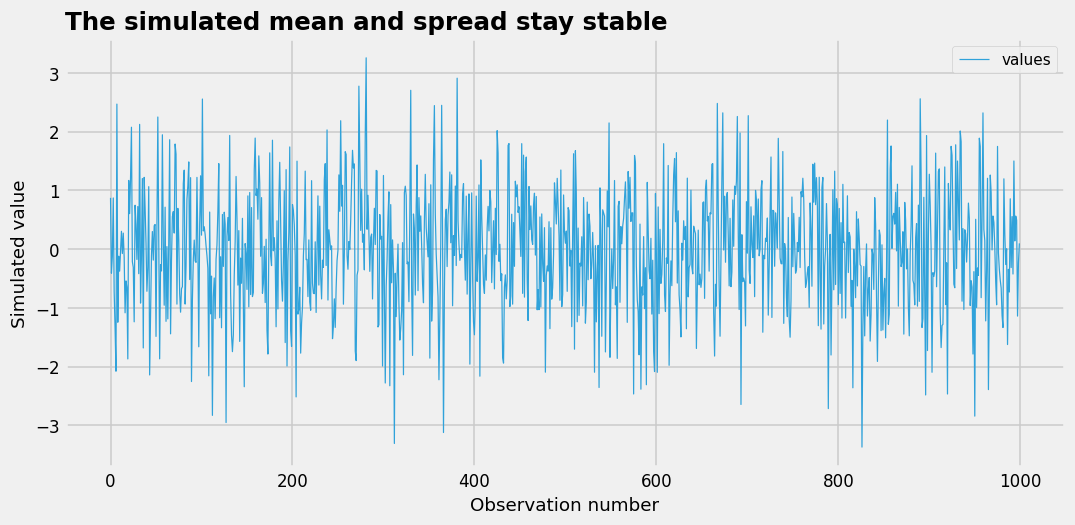

In [33]:
utils.plot_stable_simulation(time_series)

<p>The first simulation uses the same generating distribution at every observation.</p>

<h3>Change the spread</h3>

In [34]:
time_series = pd.DataFrame({'values': rng.standard_normal(1000) * np.arange(1000) * 0.1})

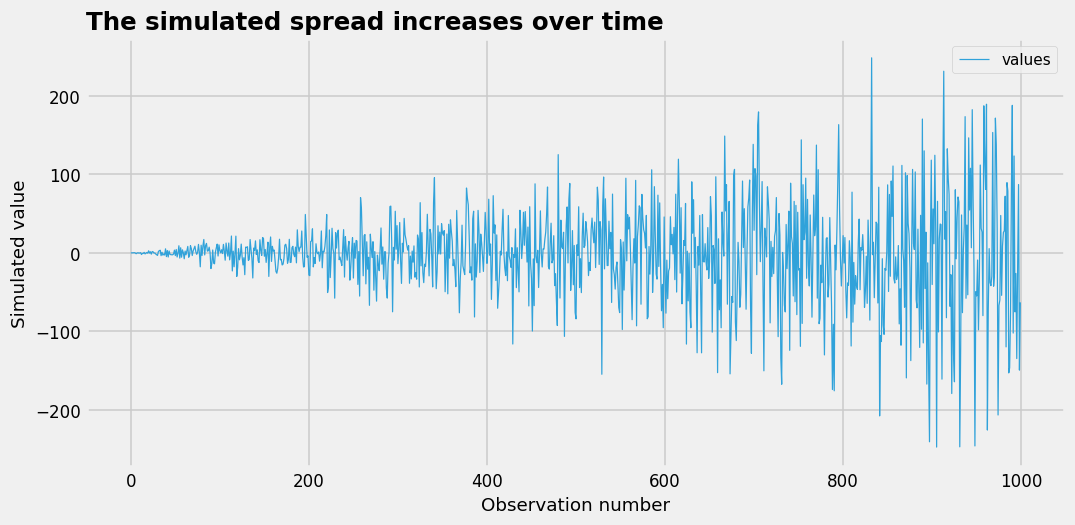

In [35]:
utils.plot_changing_spread(time_series)

<p>The multiplier grows over time, so later observations have greater spread.</p>

<h3>Change the mean</h3>

In [36]:
time_series = pd.DataFrame({'values': 20 * rng.standard_normal(1000) + np.arange(1000) * 0.1})

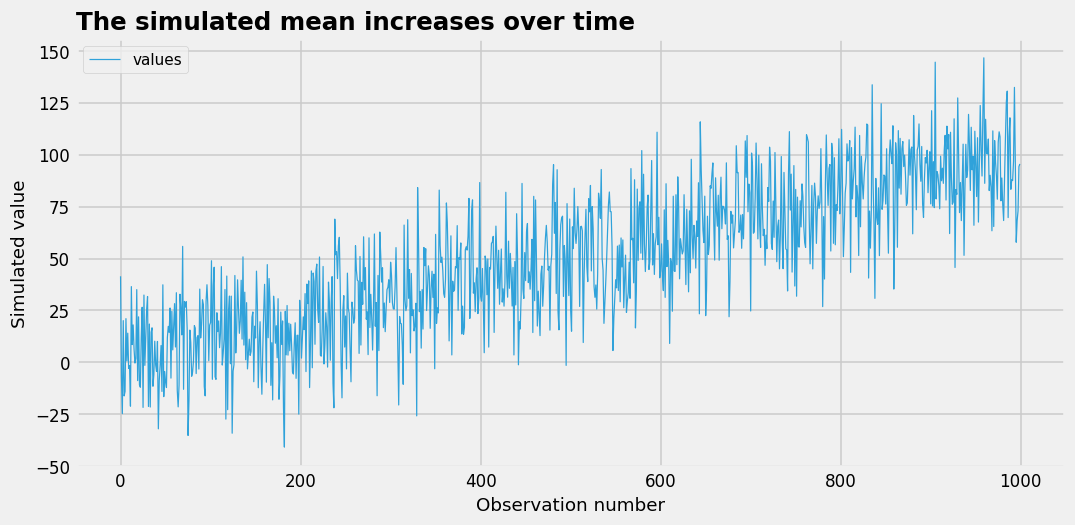

In [37]:
utils.plot_changing_mean(time_series)

<p>The added straight-line term moves the mean upward while the random spread stays fixed.</p>

<h3>Accumulate random changes</h3>

In [38]:
time_series = rng.uniform(-1, 1, 1000).cumsum()

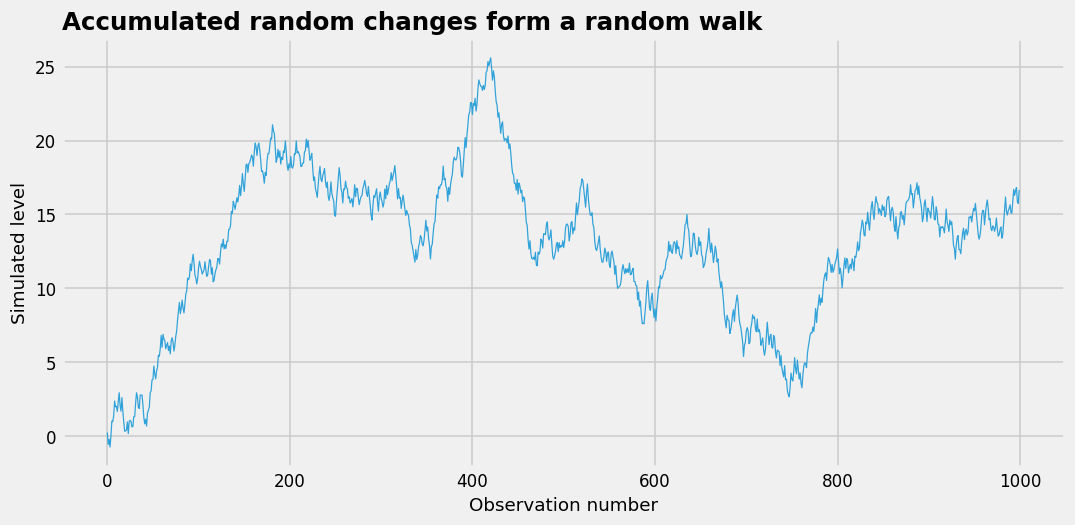

In [39]:
utils.plot_random_walk(time_series)

<p>Each value accumulates the preceding random changes. A stable distribution of changes does not imply a stationary level series.</p>

<h3>Difference the random walk</h3>

In [40]:
time_series_diff = np.diff(time_series)

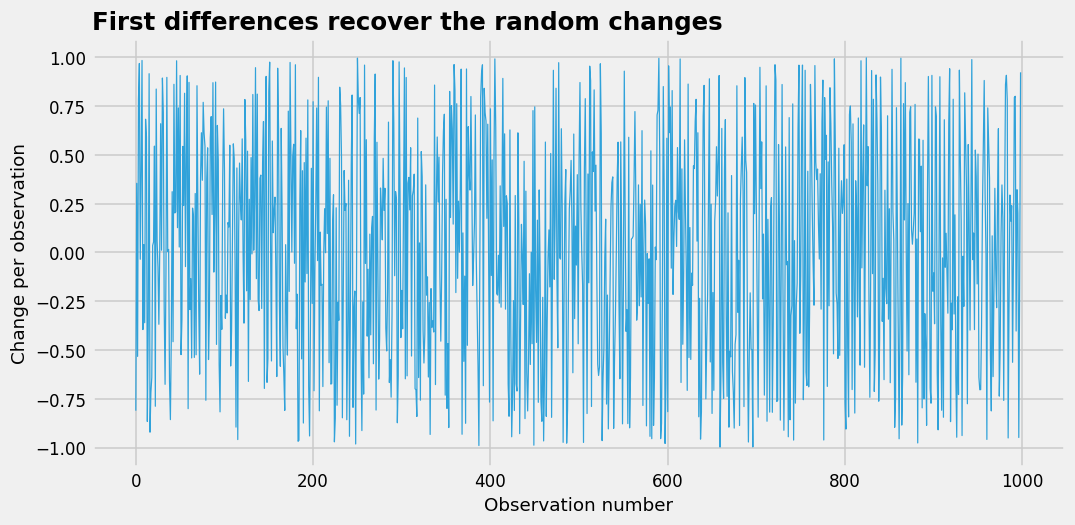

In [41]:
utils.plot_differences(time_series_diff)

<p>Differencing undoes the cumulative sum in this constructed example. Differencing a measured series does not guarantee stationarity.</p>

<p>Takeaway: Changing means, changing spread and accumulated changes produce different forms of non-stationarity.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="lecture-summary"></a><h2>Lecture summary</h2>
<ul><li>State the observation interval before interpreting a series.</li><li>Distinguish seasonality, longer cycles and trend.</li><li>Read autocorrelation alongside the time plot.</li><li>Choose totals, means and differences according to the measurement.</li><li>Preserve missing observations and document transformations.</li></ul>

<a id='section12'></a>
<h2>12. Ordering and aggregation</h2>
<p>Optional extension.</p>
<p>Question: what changes when the same bicycle counts are reordered or grouped into days?</p>

<h3>Load and reorder the hourly counts</h3>
<p>Reload the local bicycle record. Combine the two sidewalks only when both counts are present. The example week avoids daylight-saving clock changes. Shuffling values deliberately breaks the association between each timestamp and count.</p>

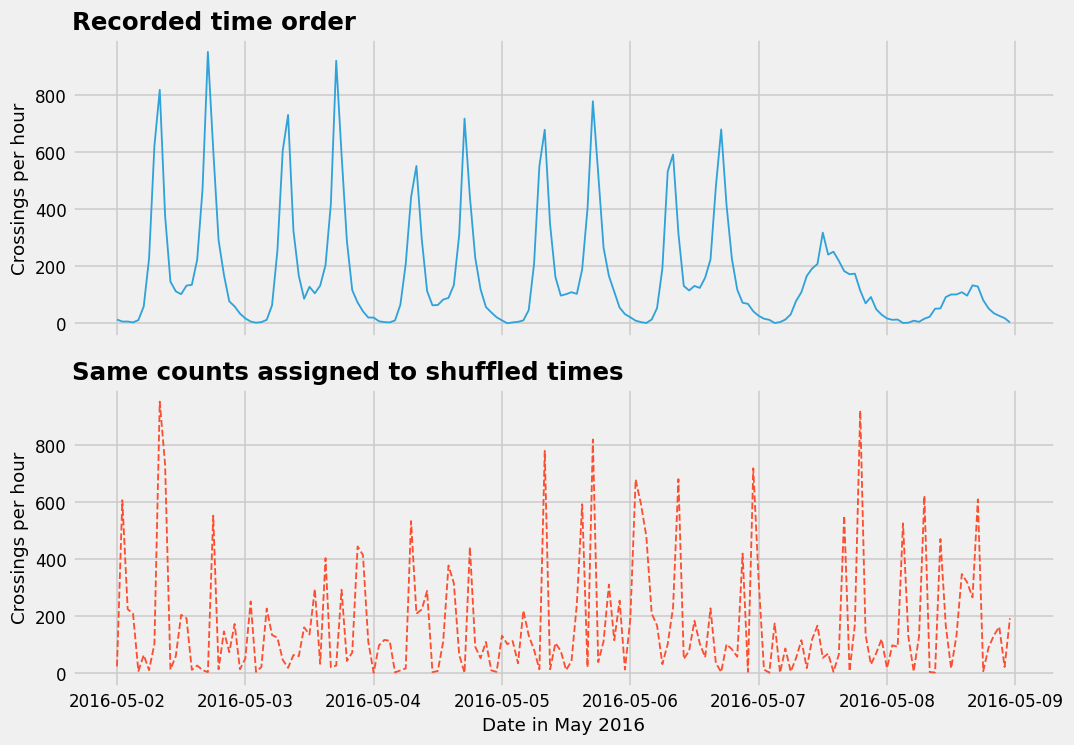

In [42]:
bikes = pd.read_csv('bike_traffic_data.csv')
bikes['Date'] = pd.to_datetime(bikes['Date'], format='%m/%d/%Y %I:%M:%S %p')
bikes = bikes.set_index('Date').sort_index()
hourly_crossings = bikes.sum(axis=1, min_count=2)
week = hourly_crossings.loc['2016-05-02':'2016-05-08']
shuffled_week = week.sample(frac=1, random_state=RANDOM_STATE)
utils.plot_ordered_and_shuffled(week, shuffled_week)

<p>The repeated daytime peaks are less distinct after shuffling. The values and their distribution stay unchanged, but their temporal relationships change.</p>

<h3>Aggregate complete days</h3>
<p>A daily total sums crossings. A daily mean instead measures crossings per recorded hour. Count the hourly readings before comparing days. This example retains only days with 24 valid readings, excluding incomplete days and daylight-saving exceptions.</p>

Days excluded from the complete-day comparison: 7


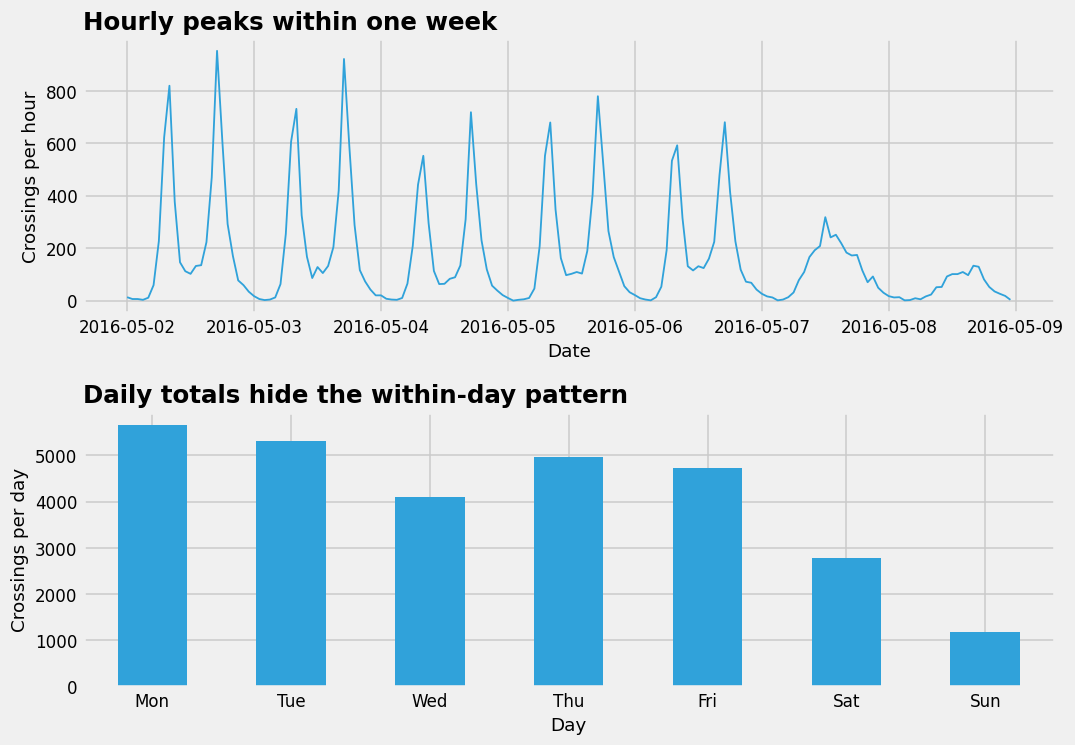

In [43]:
hour_count = hourly_crossings.resample('D').count()
daily_crossings = hourly_crossings.resample('D').sum(min_count=24)
daily_crossings = daily_crossings.where(hour_count.eq(24))
print('Days excluded from the complete-day comparison:', daily_crossings.isna().sum())
utils.plot_hourly_and_daily(week, daily_crossings)

<p>The hourly chart answers when crossings occurred. The daily chart answers how many crossings were recorded per day. The units differ, so the vertical scales answer different questions.</p>

<h3>Compare weekly profiles</h3>
<p>Group the May–September 2016 observations by weekday and hour. A heatmap displays a typical weekly profile. Each cell is the mean of observed hourly counts, rather than a total across the season.</p>

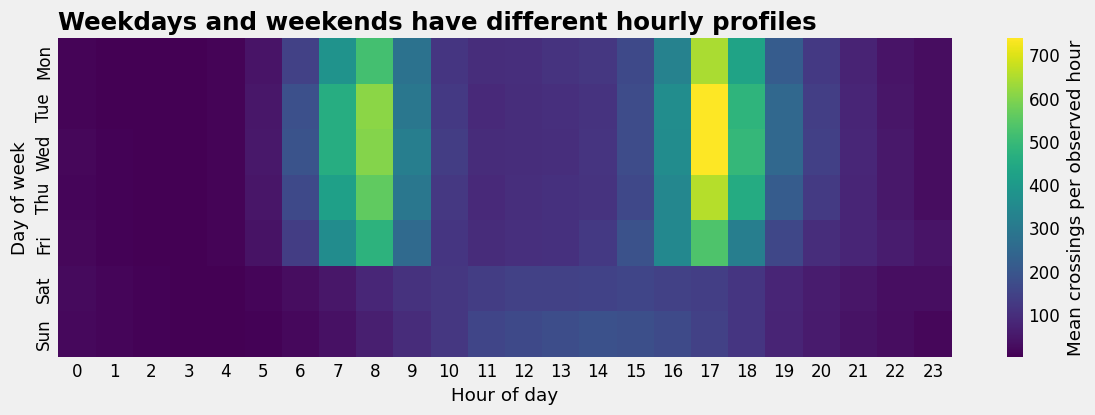

In [44]:
summer = hourly_crossings.loc['2016-05':'2016-09'].to_frame('crossings')
summer['weekday'] = summer.index.dayofweek
summer['hour'] = summer.index.hour
profile = summer.pivot_table(index='weekday', columns='hour', values='crossings', aggfunc='mean')
utils.plot_weekly_heatmap(profile)

<p>The weekday and weekend profiles differ in peak timing. The counter records crossings, so these patterns alone do not identify journey purpose.</p>

<p>Takeaway: ordering, aggregation and calendar grouping reveal different properties of the same observations.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section13'></a>
<h2>13. Seasonal profiles and decomposition</h2>
<p>Optional extension.</p>
<p>Question: how do we separate an annual temperature pattern from slower variation?</p>

<h3>Calculate a seasonal profile</h3>
<p>Use complete monthly Melbourne observations from 1990–2012. Indexing at the start of each month makes a lag of 12 correspond to twelve calendar months. A seasonal profile averages observations from the same calendar month.</p>

Missing monthly observations: 0


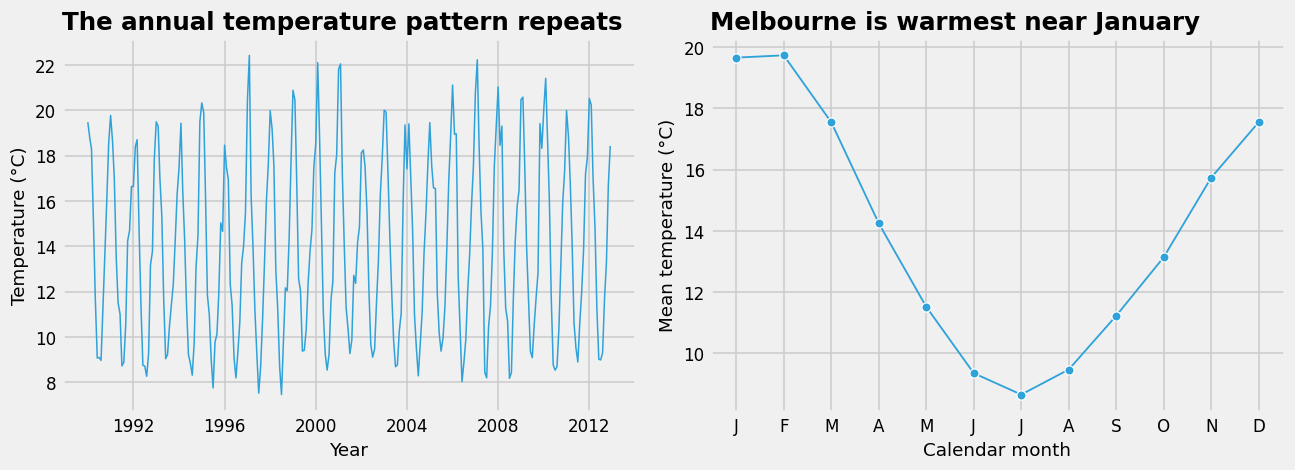

In [45]:
temperature = pd.read_csv('city_temperatures.csv', parse_dates=['dt'])
temperature = temperature.set_index('dt')['AverageTemperature'].loc['1990':'2012'].asfreq('MS')
print('Missing monthly observations:', temperature.isna().sum())
seasonal_profile = temperature.groupby(temperature.index.month).mean()
utils.plot_temperature_profile(temperature, seasonal_profile)

<p>The seasonal profile peaks in the southern-hemisphere summer. Averaging by month hides differences between individual years.</p>

<h3>Separate slower and seasonal variation</h3>
<p>Estimate slower variation with a centred twelve-month mean. Average the detrended values by calendar month, then subtract both components. This descriptive decomposition uses future observations and is unsuitable as an input available in real time.</p>

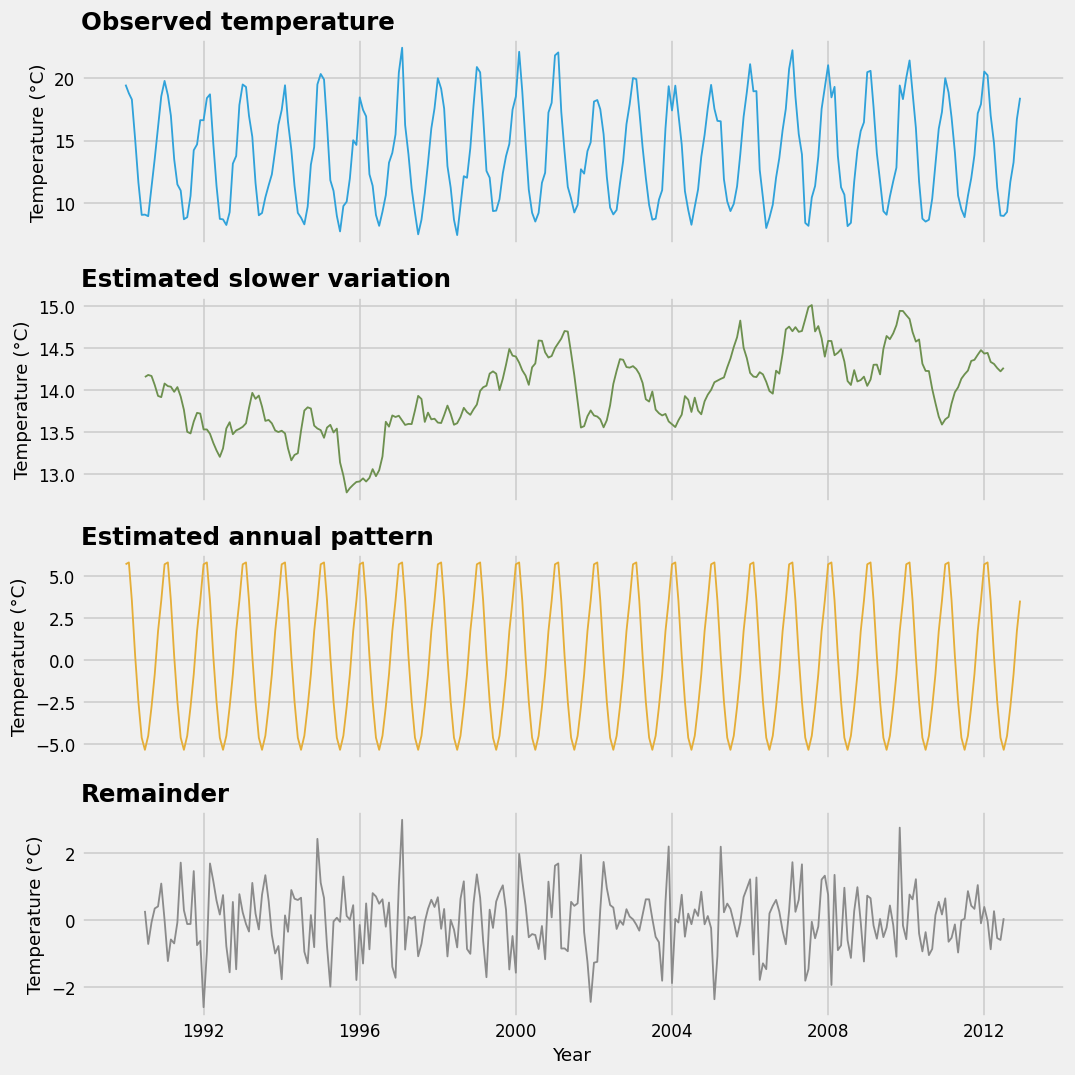

In [46]:
trend = temperature.rolling(12, center=True, min_periods=12).mean()
detrended = temperature - trend
month_effect = detrended.groupby(detrended.index.month).mean()
seasonal = pd.Series(temperature.index.month.map(month_effect), index=temperature.index)
remainder = temperature - trend - seasonal
utils.plot_decomposition(temperature, trend, seasonal, remainder)

<p>The components sum to the observed temperature wherever the centred mean exists. Empty edges reflect incomplete windows. The remainder includes measurement variation and unmodelled structure, so a small remainder does not establish independent noise.</p>

<h3>Compare ordinary and seasonal differences</h3>
<p>Compare ordinary differencing with a seasonal difference. The first subtracts the preceding month. The second subtracts the same month one year earlier. Autocorrelation compares each transformed series with shifted copies while preserving the calendar index.</p>

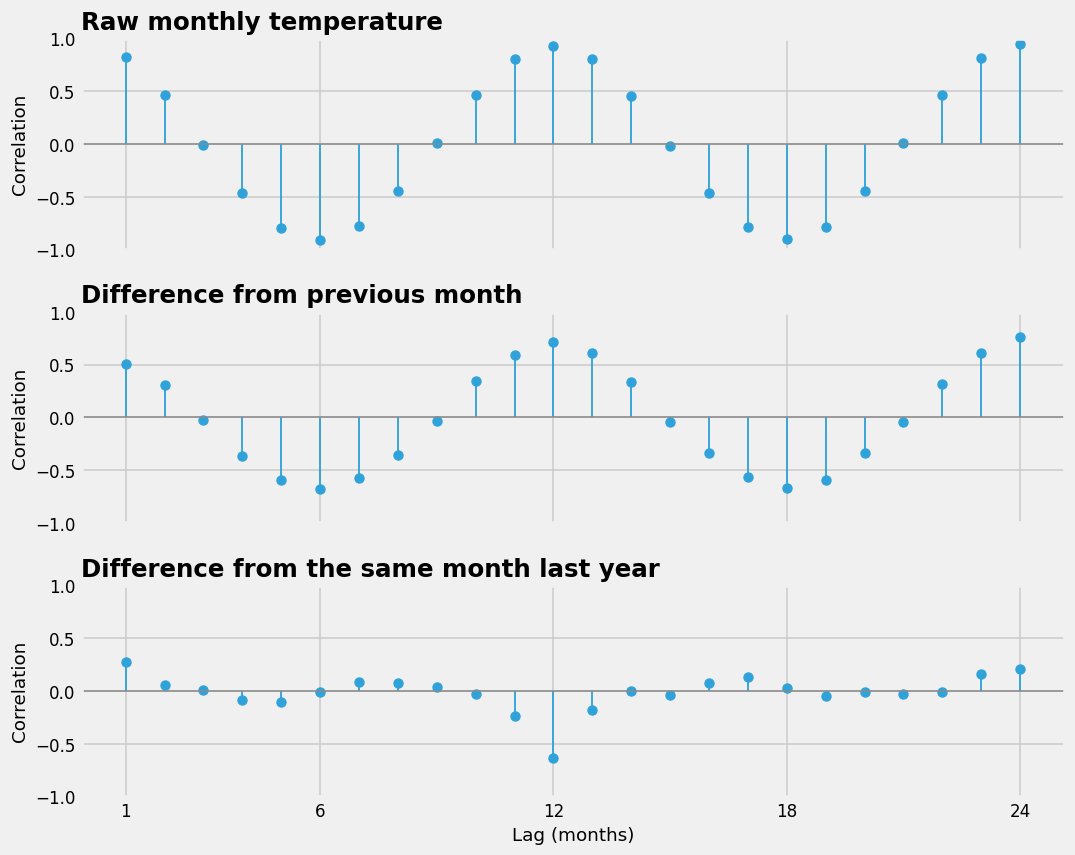

In [47]:
series = [temperature, temperature.diff(), temperature.diff(12)]
lags = range(1, 25)
correlations = [[values.autocorr(lag=k) for k in lags] for values in series]
utils.plot_differenced_autocorrelations(correlations, lags)

<p>The seasonal difference changes the strong twelve-month association. Differencing also introduces relationships between adjacent transformed values. These plots do not prove stationarity.</p>

<p>Takeaway: seasonal profiles, rolling means and differences expose different time scales. Choose each operation for a stated question.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id='section14'></a>
<h2>14. An infrastructure sensor record</h2>
<p>Optional extension.</p>
<p>Question: how should a water-level record treat missing readings, totals and rolling windows?</p>

<h3>Load an illustrative sensor record</h3>
<p>The added CSV contains constructed daily rainfall and reservoir-level readings. The values illustrate a gradual rise, a weekly operating cycle and a delayed rainfall response. Seven level readings are missing. These are teaching values, rather than measurements from a real facility.</p>

In [48]:
reservoir = pd.read_csv('illustrative_reservoir_daily.csv', parse_dates=['date']).set_index('date')
reservoir.head()

,rainfall_mm,water_level_m
date,,
2024-01-01,0.0,1.976
2024-01-02,0.0,2.045
2024-01-03,0.0,2.097
2024-01-04,12.1,2.199
2024-01-05,17.6,2.430


<p>Rainfall measures a daily depth in millimetres. Water level measures a state in metres. Their units determine the suitable aggregation.</p>

<h3>Contrast missing readings with zero</h3>
<p>Plot the two measurements on separate axes. A gap in the level trace represents absent readings. Filling the gap with zero would invent readings at the zero reference level.</p>

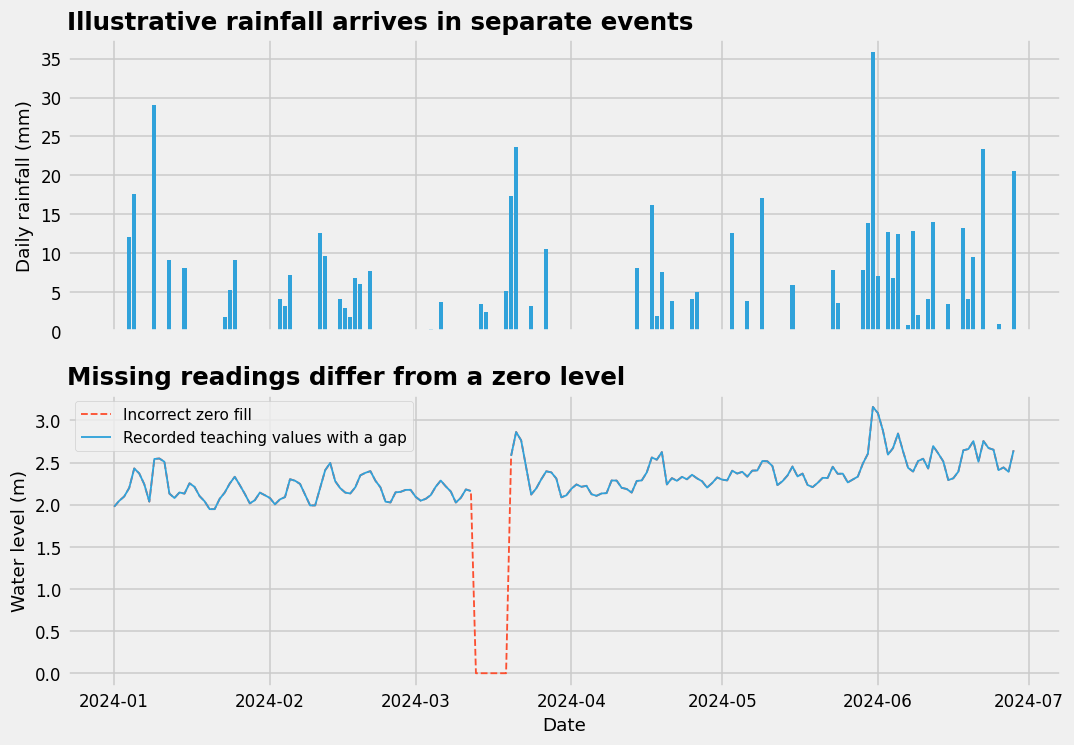

In [49]:
# Deliberately incorrect: zero is not a missing-value marker.
zero_filled_level = reservoir['water_level_m'].fillna(0)
utils.plot_sensor_gap(reservoir, zero_filled_level)

<p>The red drop exists only because of the zero-fill operation. The valid observations do not establish the water level during the gap.</p>

<h3>Choose weekly summaries</h3>
<p>Weekly rainfall is a sum of daily depths. A weekly mean level averages daily state readings. Require seven observations for either summary. An incomplete final week or sensor gap then stays missing.</p>

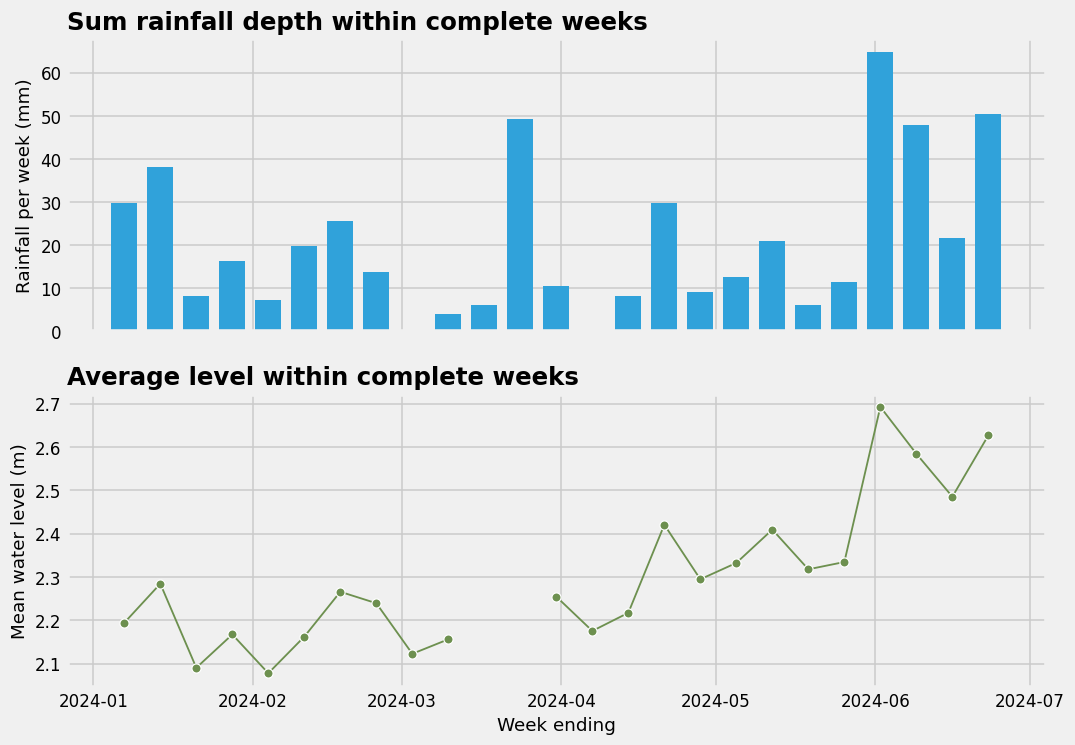

In [50]:
weekly_rainfall = reservoir['rainfall_mm'].resample('W-SUN').sum(min_count=7)
weekly_level = reservoir['water_level_m'].resample('W-SUN').mean()
weekly_readings = reservoir['water_level_m'].resample('W-SUN').count()
weekly_level = weekly_level.where(weekly_readings.eq(7))
utils.plot_reservoir_weekly(weekly_rainfall, weekly_level)

<p>Summing level readings would not yield reservoir volume. Volume requires reservoir geometry. Both weekly summaries leave incomplete weeks blank.</p>

<h3>Compare trailing and centred windows</h3>
<p>A trailing seven-day mean uses the current reading and the preceding six. A centred seven-day mean also uses the next three readings. Compare their response to the same events.</p>

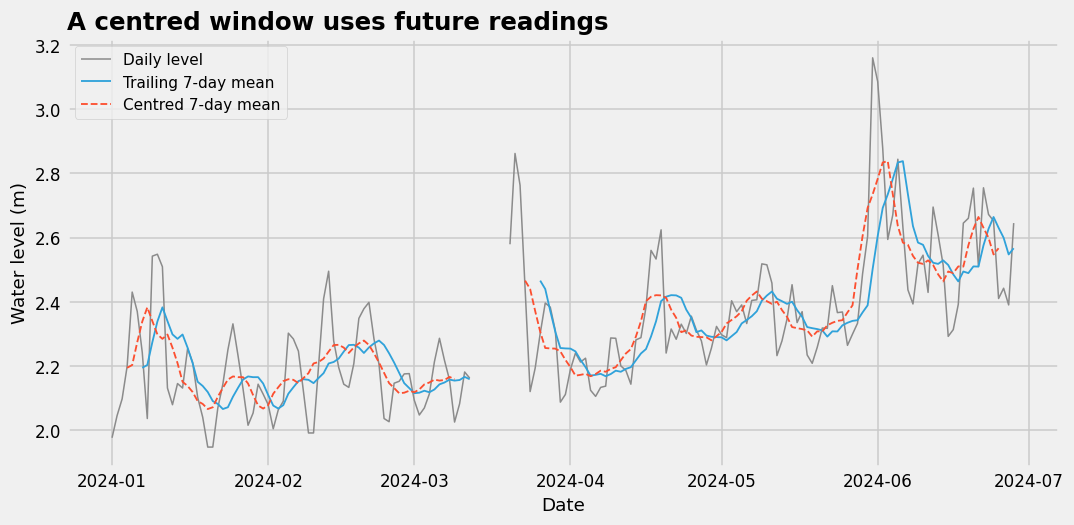

In [51]:
level = reservoir['water_level_m']
trailing = level.rolling(7, min_periods=7).mean()
centred = level.rolling(7, center=True, min_periods=7).mean()
utils.plot_rolling_windows(level, trailing, centred)

<p>The centred curve follows changes sooner because the calculation includes future readings. Use a trailing window when the current day's information is the latest available.</p>

<p>Takeaway: preserve missing readings, aggregate according to units, and distinguish historical smoothing from calculations available in real time.</p>
<p><a href="#lecture-structure">Back to Lecture Structure</a></p>